In [5]:
import numpy as np
import numpy.ma as ma
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors
from matplotlib.colors import BoundaryNorm

import matplotlib.gridspec as gridspec
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
from scipy import signal
from scipy.signal import periodogram
import eofs
import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from iris.analysis import stats
from iris.analysis import maths
import matplotlib.patches as mpatches

In [2]:
### Upload DJF PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzed/datam/pf/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['mlotst_Omon_ACCESS-ESM1-5_piControl_DJF_100yr_mean_regridded.nc',
                   'xpzed_pf_5021-5120_DJF_100yr_mean_reg.nc',
                   'mlotst_Omon_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_355001-384912_regridded_360x385_DJF_100yr_mean.nc',
                   'H0K_ymm_4901_5000.codeMLD_regridded_360x385_DJF_clim.nc',
                   'mlotst_Omon_MIROC-ES2L_piControl_185001-234912_clim_regridded_360x385_djf.nc',
                   'mld_NBF1850OC_f19_tn11_02.micom.hm.1600_1699_monthly_regridded_DJF_100yr_mean.nc',
                   'mlotst_Omon_NorESM2-LM_piControl_r1i1p1f1_gn_200101-210012_reg_DJF_100yr_mean_v2.nc']

constraints_djf_pi = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'mld'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'field653'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mlotst'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mlotst'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == '__xarray_dataarray_variable__'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mlotst')]

PI_models_mld_DJF = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_pi[i], constraints_djf_pi[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints_djf_pi[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints_djf_pi[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    PI_models_mld_DJF.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [3]:
### Upload DJF LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzec/datam/pf/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['mlotst_Omon_ACCESS-ESM1-5_lig127k_DJF_100yr_mean_regridded.nc',
                   'xpzeco_pf_6651-6750_DJF_100yrmean_reg.nc',
                   'mlotst_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_185001-239912_regridded_360x385_DJF_100yr_mean.nc',
                   'E7C_ymm_4901_5000.codeMLD_regridded_360x385_DJF_clim.nc',
                   'mlotst_Omon_MIROC-ES2L_lig127k_330001-339912_clim_regridded_360x385_djf.nc',
                   'mld_NBF1850OC_f19_tn11_01_127ka.micom.hm.1600_1699_monthly_regridded_DJF_100yr_mean.nc',
                   'mlotst_Omon_NorESM2-LM_lig127k_r1i1p1f1_gn_210101-220012_reg_DJF_100yr_mean_v2.nc']

constraints_djf_lig = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'mld'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'field653'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mlotst'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mlotst'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == '__xarray_dataarray_variable__'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mlotst')]

LIG_models_mld_DJF = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_lig[i], constraints_djf_lig[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints_djf_lig[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints_djf_lig[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models_mld_DJF.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [4]:
## AOU diff
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_dif = ['aou_diff_Oyr_ACCESS-ESM1-5_100ymean_regridded_360x385_intlevel.nc',
                   'aou_diff_Oyr_HadCM3_r1i1p1f1_6651-6750_regridded_385x360_ann_mean_intlevel.nc',
                   'aou_diff_Oyr_IPSL-CM6A-LR_r1i1p1f1_gn_1850-1949_regridded_360x385_100yr_mean_intlevel.nc',
                   'aou_diff_Oyr_KCM_r1i1p1f1_4901_5000_100yr_mean_intlevel.nc',
                   'aou_diff_Oyr_MIROC-ES2L_r1i1p1f2_gr1_330001-339912_regridded_360x385_100yr_mean_intlevel.nc',
                   'aou_diff_Oyr_NorESM1-F_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'aou_diff_Oyr_NorESM2-LM_r1i1p1f1_gr_2101-2200_100yr_mean_regridded_360x385_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff')]

DIFF_models_aou = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_dif[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    DIFF_models_aou.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [7]:
## Seawater age diff
### Upload PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'

models = [ 'ACCESS-ESM1-5', 'KCM', 'NorESM1-F', 'NorESM2-LM']
names_models_diff_age = ['agessc_diff_Oyr_ACCESS-ESM1-5_100ymean_regridded_360x385_intlevel.nc',
                   'agessc_diff_Oyr_KCM_r1i1p1f1_4901_5000_100yr_mean_intlevel.nc',
                   'agessc_diff_Oyr_NorESM1-F_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'agessc_diff_Oyr_NorESM2-LM_r1i1p1f1_gr_2101-2200_100yr_mean_regridded_360x385_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc_diff')]

Diff_models_age = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_diff_age[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    Diff_models_age.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

## Plotting

### Seasonal diff

In [9]:
titles = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L','NorESM1-F', 'NorESM2-LM']

### Differences
dif_mld_djf = []
for i in range (np.size(titles)):
    dif = LIG_models_mld_DJF[i].data-PI_models_mld_DJF[i].data
    dif_cube = PI_models_mld_DJF[i].copy(data = dif)
    dif_mld_djf.append(dif_cube)

Self-intersection at or near point -180 -55.572660157633834
Self-intersection at or near point -180 7.03125
Self-intersection at or near point -180 85.509239563033503
Self-intersection at or near point -180 -58.683005501353541
Self-intersection at or near point -180 -31.679952057151134
Self-intersection at or near point -180 -25.872420960288689
Self-intersection at or near point -180 -7.5596935516935826
Self-intersection at or near point -180 -38.546542582381861
Self-intersection at or near point -180 -29.894530207752201
Self-intersection at or near point -180 -15.451356078171846
Self-intersection at or near point -180 -9.0694749921993711


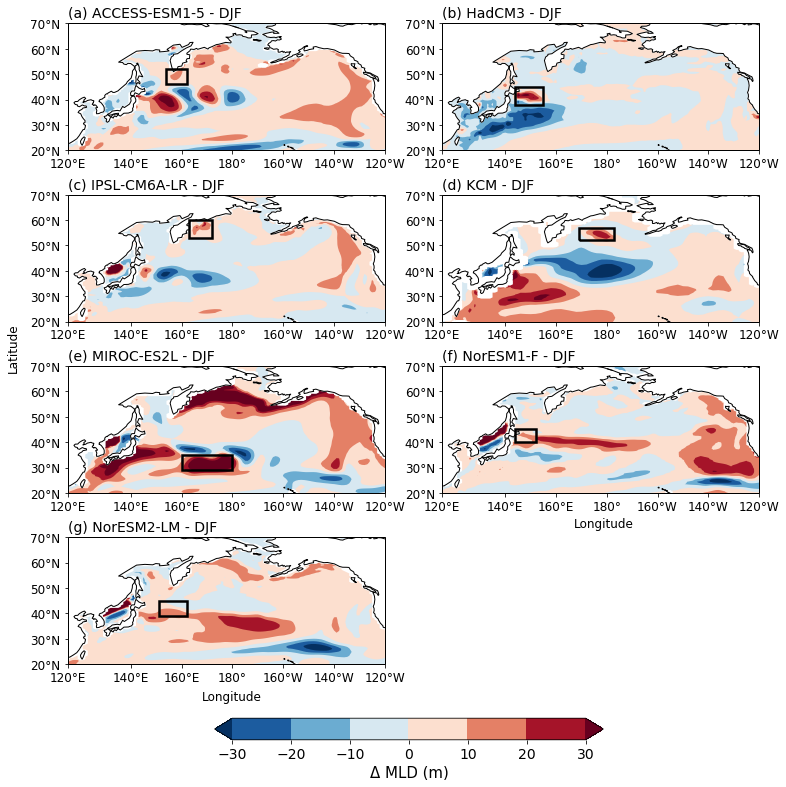

In [10]:
### MLD Pacific dif with boxes
fig = plt.figure(figsize=(12, 10))
proj = ccrs.PlateCarree(central_longitude=180)
data_crs = ccrs.PlateCarree()  # plain lon/lat for placing the boxes

titles = ['(a) ACCESS-ESM1-5', '(b) HadCM3', '(c) IPSL-CM6A-LR', '(d) KCM', '(e) MIROC-ES2L', '(f) NorESM1-F', '(g) NorESM2-LM']
sim_DJF = dif_mld_djf

# Define the box regions per subplot index: (lon_min, lon_max, lat_min, lat_max)
boxes = {
    0: (154, 162, 46, 52),
    1: (144, 155, 38, 45),
    2: (163, 172, 53, 60),
    3: (169, 183, 52, 57),
    4: (160, 180, 29, 35),
    5: (144, 152, 40, 45),
    6: (151, 162, 39, 45),
}

axes = []
for i in range(7):
    ax_djf = fig.add_subplot(4, 2, i + 1, projection=proj)
    axes.append(ax_djf)

for i, ax_djf in enumerate(axes):

    ax = ax_djf
    ax.add_feature(cartopy.feature.LAND, facecolor='white')
    ax.add_feature(cartopy.feature.COASTLINE, edgecolor='black', linewidth=1)
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    ax.set_extent([-55, 60, 20, 60], crs=proj)  # x_min, x_max, y_min, y_max

    ax.set_yticks(np.arange(20, 76, 10))
    ax.tick_params(axis='y', labelsize=12)
    ax.set_xticks([-65, -40, -20, 0, 20, 40, 60], crs=proj)
    ax.set_xticklabels(['120°E', '140°E', '160°E', '180°', '160°W', '140°W', '120°W'], fontsize=12)
    ax.tick_params(axis='x', labelsize=12)
    # Titles
    ax_djf.set_title(titles[i] + ' - DJF', fontsize=14, loc='left')
    # Plot
    im = iplt.contourf(sim_DJF[i], axes=ax_djf, cmap='RdBu_r', levels=np.arange(-30, 30 + 10, 10), extend='both')

    # Add box
    if i in boxes:
        lon_min, lon_max, lat_min, lat_max = boxes[i]
        rect = mpatches.Rectangle(
            (lon_min, lat_min),
            lon_max - lon_min,
            lat_max - lat_min,
            transform=data_crs,
            edgecolor='black',
            facecolor='none',
            linewidth=2.5,
            zorder=10)
        ax.add_patch(rect)

# Colorbar
cbar_ax = fig.add_axes([0.26, -0.045, 0.45, 0.03])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ MLD (m)', size=15)
cbar.ax.tick_params(labelsize=14)
plt.subplots_adjust(left=0.08, right=0.9, bottom=0.06, top=0.95, wspace=0.12, hspace=0.35)
# Axes labels
# Shared axis labels
fig.text(0.02, 0.5, 'Latitude', va='center', rotation='vertical', fontsize=12)
fig.text(0.28, 0.01, 'Longitude', ha='center', fontsize=12)
fig.text(0.71, 0.25, 'Longitude', ha='center', fontsize=12)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/MLD_dif_NPacific_DJF_v3_boxes.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

Self-intersection at or near point -180 -26.256406127478435
Self-intersection at or near point -180 -46.347687627680038
Self-intersection at or near point -180 -55.572660157633834
Self-intersection at or near point -180 7.03125
Self-intersection at or near point -180 85.509239563033503
Self-intersection at or near point -180 -58.683005501353541
Self-intersection at or near point -180 -57.344687807212708
Self-intersection at or near point -180 -28.609403542071014
Self-intersection at or near point -180 -54.886834411545166
Self-intersection at or near point -180 -63.291868361688124
Self-intersection at or near point -180 -31.679952057151134
Self-intersection at or near point -180 -47.952597498134011
Self-intersection at or near point -180 -57.885057599571361
Self-intersection at or near point -180 -25.872420960288689
Self-intersection at or near point -180 -60.986168032786885
Self-intersection at or near point -180 -7.9733732761412499
Self-intersection at or near point -180 0.00225936063

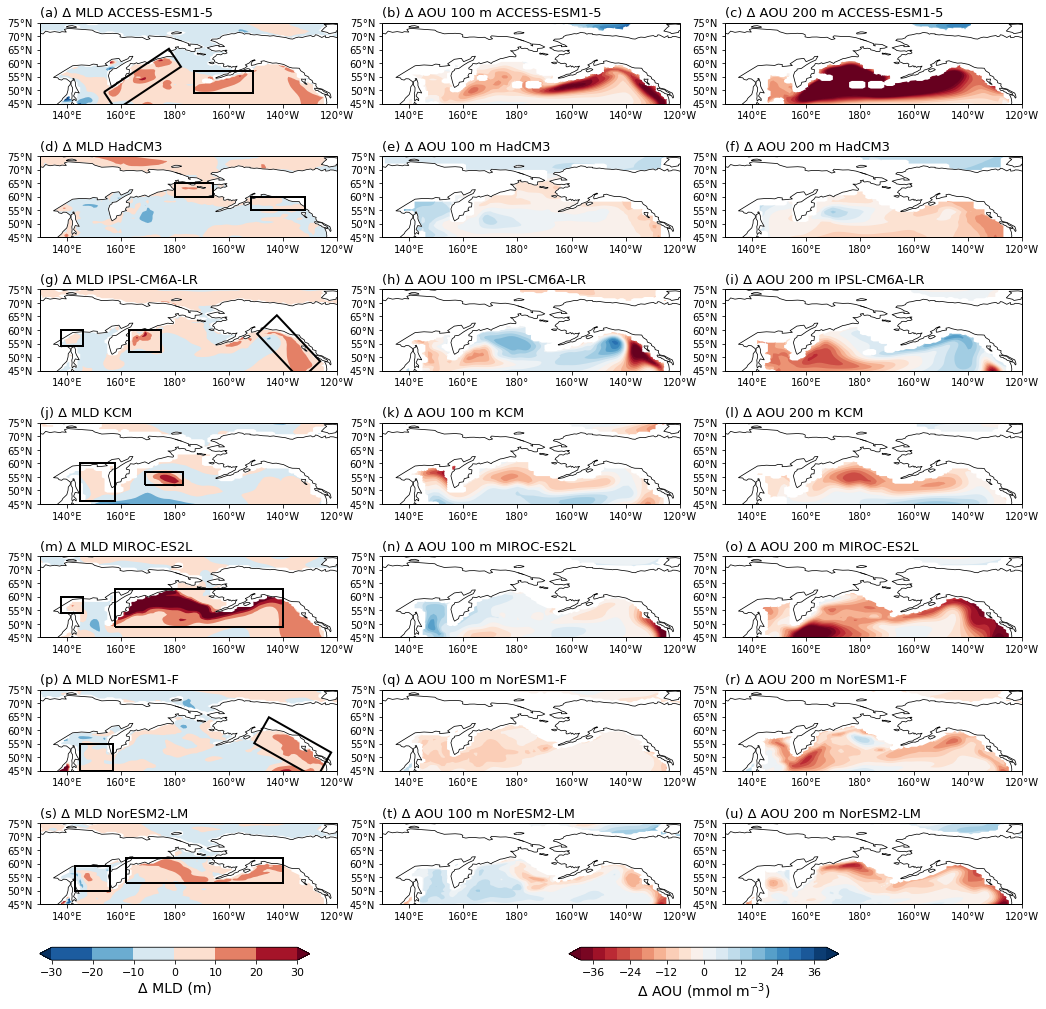

In [45]:
fig = plt.figure(figsize=(15, 15))

sim_DJF = dif_mld_djf
sim_AOU = DIFF_models_aou

proj = ccrs.PlateCarree(central_longitude=180)
data_crs = ccrs.PlateCarree()

model_names = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
letters1 = ['(a)', '(d)', '(g)', '(j)', '(m)', '(p)', '(s)']
letters2 = ['(b)', '(e)', '(h)', '(k)', '(n)', '(q)', '(t)']
letters3 = ['(c)', '(f)', '(i)', '(l)', '(o)', '(r)', '(u)']

xticks = [140, 160, 180, 200, 220, 240]
xlabels = ['140°E', '160°E', '180°', '160°W', '140°W', '120°W']

def style_axis(ax):
    ax.add_feature(cartopy.feature.LAND, facecolor='white', zorder=2)
    ax.add_feature(cartopy.feature.COASTLINE, edgecolor='black', linewidth=0.75, zorder=3)
    ax.set_extent([130, 240, 45, 70], crs=data_crs)
    ax.set_xticks(xticks, crs=data_crs)
    ax.set_xticklabels(xlabels, fontsize=10)
    ax.set_yticks(np.arange(45, 76, 5), crs=data_crs)
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    ax.tick_params(axis='both', labelsize=10)

def rotated_box_corners(lon0, lat0, lon1, lat1, width):
    """Rectangle whose long axis runs from (lon0, lat0) to (lon1, lat1);
    width is the full width in degrees, perpendicular to that axis."""
    p0 = np.array([lon0, lat0], dtype=float)
    p1 = np.array([lon1, lat1], dtype=float)
    d = (p1 - p0) / np.hypot(*(p1 - p0))      # unit vector along the axis
    n = np.array([-d[1], d[0]])               # unit normal
    h = 0.5 * width
    return [p0 + n*h, p1 + n*h, p1 - n*h, p0 - n*h]

def add_box(ax, box_list):
    for kind, b in box_list:
        if kind == 'rect':
            lon_min, lon_max, lat_min, lat_max = b
            patch = mpatches.Rectangle((lon_min, lat_min),
                                       lon_max - lon_min, lat_max - lat_min,
                                       transform=data_crs, edgecolor='black',
                                       facecolor='none', linewidth=2, zorder=10)
        else:  # 'rot'
            corners = rotated_box_corners(*b)
            patch = mpatches.Polygon(corners, closed=True,
                                     transform=data_crs, edgecolor='black',
                                     facecolor='none', linewidth=2, zorder=10)
        ax.add_patch(patch)
        
boxes = {# rot: lon0, lat0, lon1, lat1, width; rect: lon_min, lon_max, lat_min, lat_max
    0: [('rot',(156, 46, 180, 62, 8)), ('rect',(187, 209, 49, 57))],                                # ACCESS-ESM1-5
    1: [('rect',(180, 194, 60, 65)), ('rect',(208, 228, 55, 60))],                                  # HadCM3
    2: [('rect',(163, 175, 52, 60)), ('rect',(138, 146, 54, 60)), ('rot',(214, 62, 230, 45, 10))],  # IPSL-CM6A-LR
    3: [('rect',(145, 158, 46, 60)), ('rect',(169, 183, 52, 57))],                                  # KCM
    4: [('rect',(158, 220, 49, 63)), ('rect',(138, 146, 54, 60))],                                  # MIROC-ES2L
    5: [('rect',(145, 157, 45, 55)), ('rot',(212, 60, 235, 47, 11))],                               # NorESM1-F
    6: [('rect',(143, 156, 50, 59)), ('rect',(162, 220, 53, 62))],                                  # NorESM2-LM
}

mld_levels = np.arange(-30, 31, 10)
aou_levels = np.arange(-40, 41, 4)

for i in range(7):
    # Column 1: MLD
    ax_mld = fig.add_subplot(7, 3, 3*i + 1, projection=proj)
    ax_mld.set_title(letters1[i] + ' Δ MLD ' + model_names[i], fontsize=13, loc='left')
    style_axis(ax_mld)
    im_mld = iplt.contourf(sim_DJF[i], axes=ax_mld, cmap='RdBu_r', levels=mld_levels, extend='both')
    add_box(ax_mld, boxes[i])

    # Column 2: AOU 100 m
    ax_aou1 = fig.add_subplot(7, 3, 3*i + 2, projection=proj)
    ax_aou1.set_title(letters2[i] + ' Δ AOU 100 m ' + model_names[i], fontsize=13, loc='left')
    style_axis(ax_aou1)
    im_aou = iplt.contourf(sim_AOU[i][25], axes=ax_aou1, cmap='RdBu', levels=aou_levels, extend='both')
    #add_box(ax_aou1, boxes[i])

    # Column 3: AOU 200 m
    ax_aou2 = fig.add_subplot(7, 3, 3*i + 3, projection=proj)
    ax_aou2.set_title(letters3[i] + ' Δ AOU 200 m ' + model_names[i], fontsize=13, loc='left')
    style_axis(ax_aou2)
    im_aou = iplt.contourf(sim_AOU[i][31], axes=ax_aou2, cmap='RdBu', levels=aou_levels, extend='both')
    #add_box(ax_aou2, boxes[i])

# Make room at the bottom for the colorbars
plt.subplots_adjust(left=0.06, right=0.97, top=0.96, bottom=0.12,wspace=0.15, hspace=0.25)

# Colorbars (same height, below the bottom row)
cax1 = fig.add_axes([0.06, 0.08, 0.25, 0.012])
cb1 = fig.colorbar(im_mld, cax=cax1, orientation='horizontal')
cb1.set_label('Δ MLD (m)', fontsize=14)
cb1.ax.tick_params(labelsize=11)

cax2 = fig.add_axes([0.55, 0.08, 0.25, 0.012])
cb2 = fig.colorbar(im_aou, cax=cax2, orientation='horizontal')
cb2.set_label('Δ AOU (mmol m$^{-3}$)', fontsize=14)
cb2.ax.tick_params(labelsize=11)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/MLD_AOU_200m_diff_NPacific_DJF_boxes.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

In [11]:
### Rearrange MLD so that fits age 4 models 
#print(dif_mld_djf)
dif_mld_djf2 = [dif_mld_djf[0], dif_mld_djf[3], dif_mld_djf[5], dif_mld_djf[6]]

Self-intersection at or near point -180 78.903369855130705
Self-intersection at or near point -180 -8.8581798458939183
Self-intersection at or near point -180 -7.5596935516935826
Self-intersection at or near point -180 -38.546542582381861
Self-intersection at or near point -180 -29.894530207752201
Self-intersection at or near point -180 -15.451356078171846
Self-intersection at or near point -180 -9.0694749921993711
Self-intersection at or near point -180 -50.715493336466402
Self-intersection at or near point -180 -34.971156048755695
Self-intersection at or near point -180 -68.045235024112174
Self-intersection at or near point -180 -58.146192487793762
Self-intersection at or near point -180 -46.411225533170928
Self-intersection at or near point -180 -43.833835617910424
Self-intersection at or near point -180 -2.8525418850428874
Self-intersection at or near point -180 -3.8076343061439841


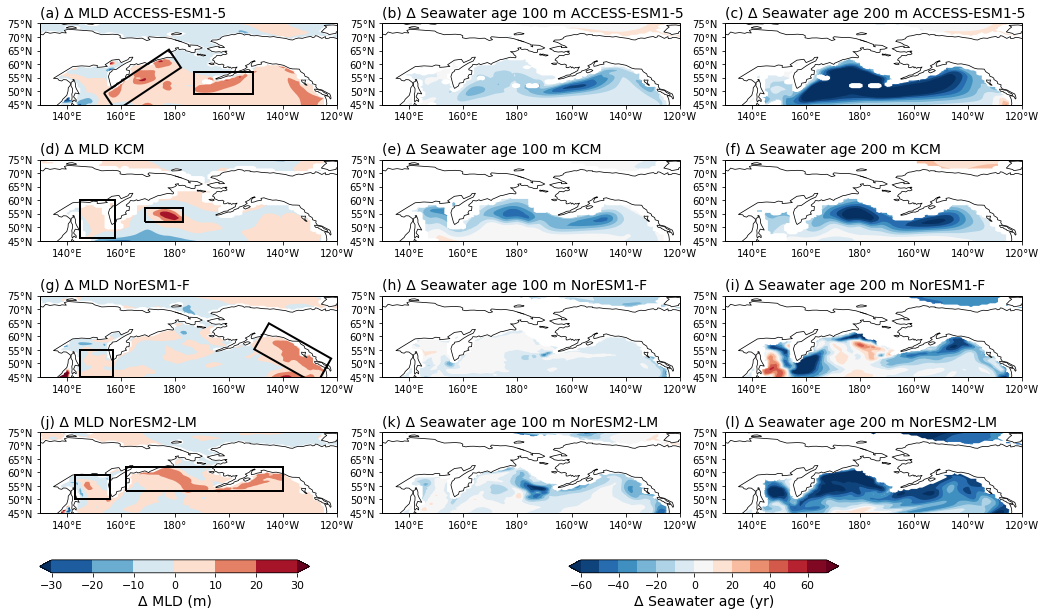

In [17]:
fig = plt.figure(figsize=(15, 9))

sim_DJF = dif_mld_djf2
sim_age = Diff_models_age

proj = ccrs.PlateCarree(central_longitude=180)
data_crs = ccrs.PlateCarree()

model_names = ['ACCESS-ESM1-5', 'KCM', 'NorESM1-F', 'NorESM2-LM']
letters1 = ['(a)', '(d)', '(g)', '(j)']
letters2 = ['(b)', '(e)', '(h)', '(k)']
letters3 = ['(c)', '(f)', '(i)', '(l)']

xticks = [140, 160, 180, 200, 220, 240]
xlabels = ['140°E', '160°E', '180°', '160°W', '140°W', '120°W']

def style_axis(ax):
    ax.add_feature(cartopy.feature.LAND, facecolor='white', zorder=2)
    ax.add_feature(cartopy.feature.COASTLINE, edgecolor='black', linewidth=0.75, zorder=3)
    ax.set_extent([130, 240, 45, 70], crs=data_crs)
    ax.set_xticks(xticks, crs=data_crs)
    ax.set_xticklabels(xlabels, fontsize=10)
    ax.set_yticks(np.arange(45, 76, 5), crs=data_crs)
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    ax.tick_params(axis='both', labelsize=10)

def rotated_box_corners(lon0, lat0, lon1, lat1, width):
    """Rectangle whose long axis runs from (lon0, lat0) to (lon1, lat1);
    width is the full width in degrees, perpendicular to that axis."""
    p0 = np.array([lon0, lat0], dtype=float)
    p1 = np.array([lon1, lat1], dtype=float)
    d = (p1 - p0) / np.hypot(*(p1 - p0))      # unit vector along the axis
    n = np.array([-d[1], d[0]])               # unit normal
    h = 0.5 * width
    return [p0 + n*h, p1 + n*h, p1 - n*h, p0 - n*h]

def add_box(ax, box_list):
    for kind, b in box_list:
        if kind == 'rect':
            lon_min, lon_max, lat_min, lat_max = b
            patch = mpatches.Rectangle((lon_min, lat_min),
                                       lon_max - lon_min, lat_max - lat_min,
                                       transform=data_crs, edgecolor='black',
                                       facecolor='none', linewidth=2, zorder=10)
        else:  # 'rot'
            corners = rotated_box_corners(*b)
            patch = mpatches.Polygon(corners, closed=True,
                                     transform=data_crs, edgecolor='black',
                                     facecolor='none', linewidth=2, zorder=10)
        ax.add_patch(patch)
        
boxes2 = {# rot: lon0, lat0, lon1, lat1, width; rect: lon_min, lon_max, lat_min, lat_max
    0: [('rot',(156, 46, 180, 62, 8)), ('rect',(187, 209, 49, 57))],                                 # ACCESS-ESM1-5
    #1: [('rect',(180, 194, 60, 65)), ('rect',(208, 228, 55, 60))],                                  # HadCM3
    #2: [('rect',(163, 175, 52, 60)), ('rect',(138, 146, 54, 60)), ('rot',(214, 62, 230, 45, 10))],  # IPSL-CM6A-LR
    1: [('rect',(145, 158, 46, 60)), ('rect',(169, 183, 52, 57))],                                   # KCM
    #4: [('rect',(158, 220, 49, 63)), ('rect',(138, 146, 54, 60))],                                  # MIROC-ES2L
    2: [('rect',(145, 157, 45, 55)), ('rot',(212, 60, 235, 47, 11))],                                # NorESM1-F
    3: [('rect',(143, 156, 50, 59)), ('rect',(162, 220, 53, 62))],                                   # NorESM2-LM
}

mld_levels = np.arange(-30, 31, 10)
age_levels = np.arange(-60, 61+10, 10)

for i in range(4):
    # Column 1: MLD
    ax_mld = fig.add_subplot(4, 3, 3*i + 1, projection=proj)
    ax_mld.set_title(letters1[i] + ' Δ MLD ' + model_names[i], fontsize=14, loc='left')
    style_axis(ax_mld)
    im_mld = iplt.contourf(sim_DJF[i], axes=ax_mld, cmap='RdBu_r', levels=mld_levels, extend='both')
    #add_box(ax_mld, boxes[i])
    add_box(ax_mld, boxes2.get(i, []))

    # Column 2: AOU 100 m
    ax_aou1 = fig.add_subplot(4, 3, 3*i + 2, projection=proj)
    ax_aou1.set_title(letters2[i] + ' Δ Seawater age 100 m ' + model_names[i], fontsize=14, loc='left')
    style_axis(ax_aou1)
    im_aou = iplt.contourf(sim_age[i][25], axes=ax_aou1, cmap='RdBu_r', levels=age_levels, extend='both')
    #add_box(ax_aou1, boxes[i])

    # Column 3: AOU 200 m
    ax_aou2 = fig.add_subplot(4, 3, 3*i + 3, projection=proj)
    ax_aou2.set_title(letters3[i] + ' Δ Seawater age 200 m ' + model_names[i], fontsize=14, loc='left')
    style_axis(ax_aou2)
    im_aou = iplt.contourf(sim_age[i][31], axes=ax_aou2, cmap='RdBu_r', levels=age_levels, extend='both')
    #add_box(ax_aou2, boxes[i])

# Make room at the bottom for the colorbars
plt.subplots_adjust(left=0.06, right=0.97, top=0.96, bottom=0.12,wspace=0.15, hspace=0.001)

# Colorbars (same height, below the bottom row)
cax1 = fig.add_axes([0.06, 0.07, 0.25, 0.02])
cb1 = fig.colorbar(im_mld, cax=cax1, orientation='horizontal')
cb1.set_label('Δ MLD (m)', fontsize=14)
cb1.ax.tick_params(labelsize=11)

cax2 = fig.add_axes([0.55, 0.07, 0.25, 0.02])
cb2 = fig.colorbar(im_aou, cax=cax2, orientation='horizontal')
cb2.set_label('Δ Seawater age (yr)', fontsize=14)
cb2.ax.tick_params(labelsize=11)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/MLD_Age_200m_diff_NPacific_DJF_boxes.png', bbox_inches='tight', dpi=300, format='png')
plt.show()